# TPC全体のエネルギースペクトルと二次補正

ゲインマップ適用後の**イベントごとのTPC全体エネルギー**を使います。1-hitの選別はしません。
`TPC_Calibration`と同じく、同時計数で各ch組の寄与を重み付けします。未較正の組（Ka=Kb=0）は寄与0とし、その領域を含むイベントも使います。
全体のエネルギーが0のイベントは既存モジュールのSpectrumには入りません。

入力ROOTにはFADCと飛跡ヒットが必要です。ヒット未保存の古いROOT（今回のrun13など）は、この手順では使えません。

In [30]:
from pathlib import Path
import sys,json,subprocess
import numpy as np
import matplotlib.pyplot as plt
import ROOT
ROOT.gROOT.SetBatch(True)
REPO=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'run_script/run_chain.py').exists())
sys.path.insert(0,str(REPO/'scripts/calib'))
from tpc_energy_calibration import fit_peak,gaussian_linear,quadratic_calibration,evaluate,write_correction
D=Path('/home/onoda/hikaru3_analysis2/SMILE3-FM_analysis/20261113')
RAWS=[D/f'tpc_raw_20261113_{r}.root' for r in ['run13_2','run14','run15','run16','run17']]
GAIN_MAP=Path('/home/onoda/hikaru3_analysis2/SMILE3-FM_analysis/20261113/tpc_gain_20261113_run13-17/gain_map.dat')
OUT=Path('/home/onoda/hikaru3_analysis2/SMILE3-FM_analysis/20261113/tpc_gain_20261113_run13-17/all_gain_correction')
BASE_WINDOW=30.0  # ベースラインの長さ [sample]
THRESHOLD=20.0  # 積分閾値 [ADU above baseline]
for p in [*RAWS,GAIN_MAP,OUT]:
    if '<' in str(p): raise ValueError('入力・出力パスを指定してください')
OUT.mkdir(parents=True,exist_ok=True)


## 1. ゲインマップを適用してイベントを解析
既存のTPCチェーンを使います。未較正の組がファイル中でKa=Kb=0になっていることを確認します。出力が存在すれば再利用します。ゲインや積分条件を変えるときは出力先も変えてください。

In [31]:
gain=np.loadtxt(GAIN_MAP,ndmin=2)
if gain.shape[1]!=4 or not np.isfinite(gain).all():raise ValueError('gain mapの形式が不正です')
if np.any((gain[:,2]==0)&(gain[:,3]!=0)):raise ValueError('未較正の組はKa=Kb=0にしてください')
print('較正済みの組:',int((gain[:,2]!=0).sum()),'/',len(gain))
import hashlib
FILES=[]
for i,raw in enumerate(RAWS):
    f=ROOT.TFile.Open(str(raw))
    from sys import path
    path.insert(0,str(REPO/'scripts/analysis'))
    from tpc_raw_io import raw_tree_path
    t=f.Get(raw_tree_path(raw))
    if not t.GetBranch('hit_a_strip') or not t.GetBranch('hit_c_strip'):raise ValueError(f'{raw}: 飛跡ヒットが未保存です')
    f.Close()
    target=OUT/f'energy_{i:03d}.root'
    cmd=[sys.executable,str(REPO/'run_script/run_chain.py'),'smile3_tpc_energy','--root-input',str(raw),'-o',str(target),
         '--set','TPC_Calibration.NoCalData=false','--set',f'TPC_Calibration.ParameterFile={GAIN_MAP}',
         '--set','TPC_Calibration.Spectrum_TH=true','--set',f'CalcFADC.base_window={BASE_WINDOW}',
         '--set',f'CalcFADC.threshold={THRESHOLD}']
    print(' '.join(cmd))
    provenance={'command':cmd,'gain_map_sha256':hashlib.sha256(GAIN_MAP.read_bytes()).hexdigest(),'raw_size':raw.stat().st_size,'raw_mtime_ns':raw.stat().st_mtime_ns}
    stamp=target.with_suffix('.inputs.json')
    if target.exists() and (not stamp.exists() or json.loads(stamp.read_text())!=provenance):
        raise RuntimeError(f'{target}: 入力または条件を確認できません。別の出力フォルダを指定してください')
    if not target.exists():
        with target.with_suffix('.log').open('w') as log:subprocess.run(cmd,stdout=log,stderr=subprocess.STDOUT,check=True)
        stamp.write_text(json.dumps(provenance,ensure_ascii=False,indent=2))
    FILES.append(target)


較正済みの組: 230 / 576
/usr/bin/python /home/onoda/ANLNext/Erica_git_dev/EricaNext/run_script/run_chain.py smile3_tpc_energy --root-input /home/onoda/hikaru3_analysis2/SMILE3-FM_analysis/20261113/tpc_raw_20261113_run13_2.root -o /home/onoda/hikaru3_analysis2/SMILE3-FM_analysis/20261113/tpc_gain_20261113_run13-17/all_gain_correction/energy_000.root --set TPC_Calibration.NoCalData=false --set TPC_Calibration.ParameterFile=/home/onoda/hikaru3_analysis2/SMILE3-FM_analysis/20261113/tpc_gain_20261113_run13-17/gain_map.dat --set TPC_Calibration.Spectrum_TH=true --set CalcFADC.base_window=30.0 --set CalcFADC.threshold=20.0
/usr/bin/python /home/onoda/ANLNext/Erica_git_dev/EricaNext/run_script/run_chain.py smile3_tpc_energy --root-input /home/onoda/hikaru3_analysis2/SMILE3-FM_analysis/20261113/tpc_raw_20261113_run14.root -o /home/onoda/hikaru3_analysis2/SMILE3-FM_analysis/20261113/tpc_gain_20261113_run13-17/all_gain_correction/energy_001.root --set TPC_Calibration.NoCalData=false --set TPC_Calibrati

## 2. 全イベントのエネルギースペクトル
各runのイベントスペクトルを合計します。未較正領域の寄与0により、部分的なエネルギーになるイベントも含まれます。

/home/onoda/hikaru3_analysis2/SMILE3-FM_analysis/20261113/tpc_gain_20261113_run13-17/all_gain_correction/energy_000.root entries= 12229336.0 underflow= 1498403.0 overflow= 14429.0
/home/onoda/hikaru3_analysis2/SMILE3-FM_analysis/20261113/tpc_gain_20261113_run13-17/all_gain_correction/energy_001.root entries= 5926878.0 underflow= 371776.0 overflow= 9671.0
/home/onoda/hikaru3_analysis2/SMILE3-FM_analysis/20261113/tpc_gain_20261113_run13-17/all_gain_correction/energy_002.root entries= 53909.0 underflow= 7279.0 overflow= 100.0
/home/onoda/hikaru3_analysis2/SMILE3-FM_analysis/20261113/tpc_gain_20261113_run13-17/all_gain_correction/energy_003.root entries= 3822297.0 underflow= 310102.0 overflow= 7809.0
/home/onoda/hikaru3_analysis2/SMILE3-FM_analysis/20261113/tpc_gain_20261113_run13-17/all_gain_correction/energy_004.root entries= 7947678.0 underflow= 735327.0 overflow= 17275.0


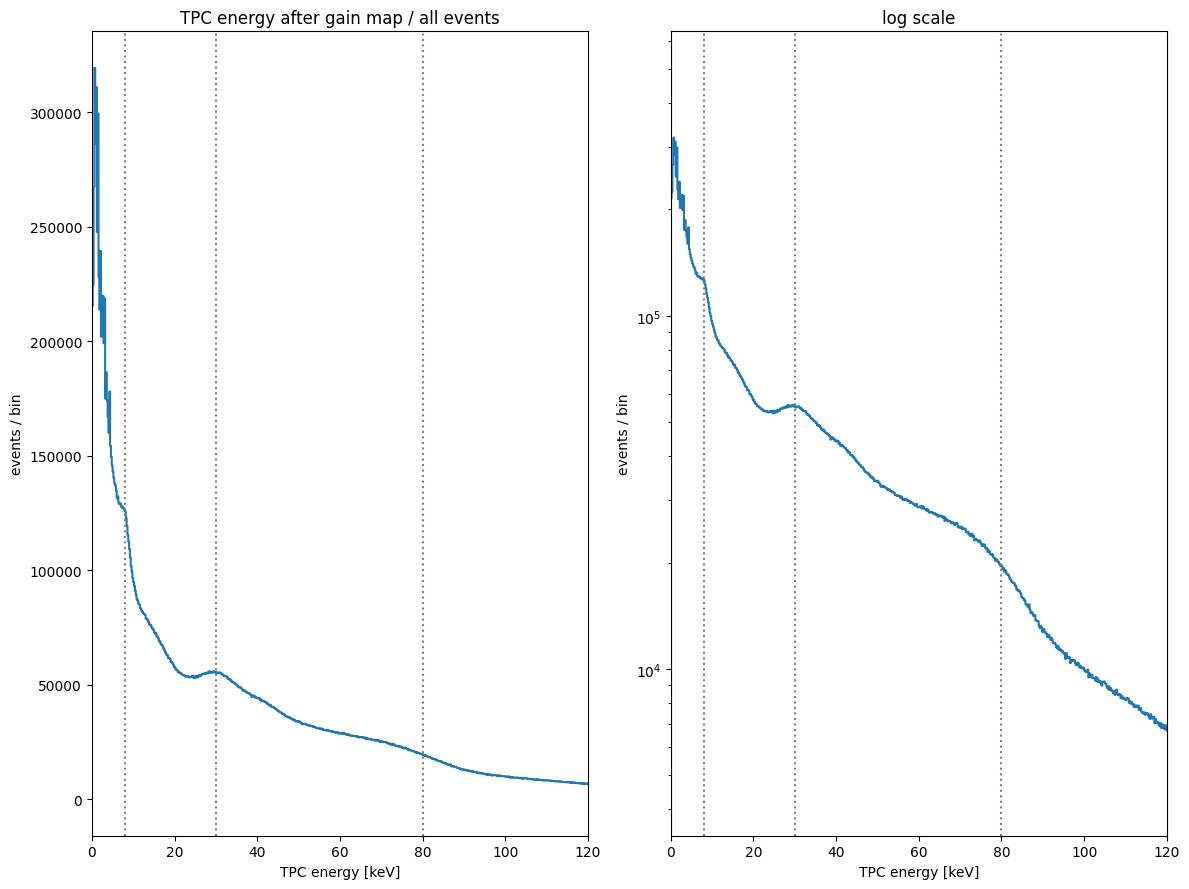

In [32]:
hist=None
for target in FILES:
    f=ROOT.TFile.Open(str(target));h=f.Get('TPC_Calibration/Spectrum')
    if not h:raise RuntimeError(f'{target}: Spectrumがありません')
    print(target,'entries=',h.GetEntries(),'underflow=',h.GetBinContent(0),'overflow=',h.GetBinContent(h.GetNbinsX()+1))
    if hist is None:hist=h.Clone('Spectrum_gain');hist.SetDirectory(0)
    else:hist.Add(h)
    f.Close()
edges=np.array([hist.GetXaxis().GetBinLowEdge(i) for i in range(1,hist.GetNbinsX()+2)])
counts=np.array([hist.GetBinContent(i) for i in range(1,hist.GetNbinsX()+1)])
x=(edges[:-1]+edges[1:])/2
fig,axs=plt.subplots(1,2,figsize=(12,9))
for ax in axs:
    ax.step(x,counts,where='mid');ax.set(xlim=(0,120),xlabel='TPC energy [keV]',ylabel='events / bin')
    for e in (8,30,80):ax.axvline(e,ls=':',color='gray')
axs[0].set_title('TPC energy after gain map / all events')
inside=counts[(x>0)&(x<=120)];axs[1].set_yscale('log');axs[1].set_ylim(0.5*inside[inside>0].min(),2*inside.max());axs[1].set_title('log scale')
fig.tight_layout();fig.savefig(OUT/'spectrum_gain.png',dpi=150);plt.show()
f=ROOT.TFile(str(OUT/'spectrum_gain.root'),'RECREATE');hist.Write();f.Close()


## 3. Cu・Baの3ピークをフィット

ガウス＋直線背景で中心と標準誤差を求めます。範囲は図を見て調整してください。
基準値は候補です。Cu Kαと約30 keVのX線群は重なった線の有効エネルギーをどう扱うか確認し、`REFERENCES_CONFIRMED=True`にしてから保存します。
Cuの線は [NIST](https://physics.nist.gov/cgi-bin/XrayTrans/search.pl?element=Cu&trans=All&units=eV)、Ba-133の核データは [LNHB](https://www.lnhb.fr/nuclides/Ba-133_com.pdf) を参照。


**手動で fit する**: `INITIAL`(初期値)と `FIXED`(固定する値)を、ピークごとに `{名前: 値}` で書きます。空の `{}` なら自動です。
名前は `amplitude`(ガウスの高さ [events/bin])、`mean`(中心 [keV])、`sigma`(幅 [keV])、`b0`(中心での背景 [events/bin])、`b1`(背景の傾き [events/bin/keV])。
`mean` は固定できません(中心の誤差が較正に要るため)。図の灰色の点線が初期値の曲線、緑の点線が fit したガウス(右の縦軸)、赤の点線が fit した背景です。
固定したパラメータは誤差 0 として扱うので、中心の誤差はその分小さく出ます。

{'mean': 8.06207122990672, 'mean_error': 0.015911131545997718, 'sigma': 0.7685438989168555, 'chi2ndf': 2.7262318341308767, 'initial': {'amplitude': 12603.583333333343, 'mean': 8.100000000000001, 'sigma': 0.7142857142857143, 'b0': 113038.41666666666, 'b1': -9177.291666666666}, 'fixed': {}, 'accepted': True, 'reasons': []}
{'mean': 30.741694734147956, 'mean_error': 0.05073694376934518, 'sigma': 3.6348715838771817, 'chi2ndf': 1.434182053749738, 'initial': {'amplitude': 6027.7752808988735, 'mean': 30.9, 'sigma': 2.5714285714285716, 'b0': 49310.22471910113, 'b1': -557.2471910112358}, 'fixed': {}, 'accepted': True, 'reasons': []}
{'mean': 72.49005723741206, 'mean_error': 0.10888140545358213, 'sigma': 7.0125119902228334, 'chi2ndf': 2.243870022849078, 'initial': {'amplitude': 1747.9464285714275, 'mean': 72.9, 'sigma': 6.428571428571429, 'b0': 22404.053571428572, 'b1': -512.3660714285713}, 'fixed': {}, 'accepted': True, 'reasons': []}


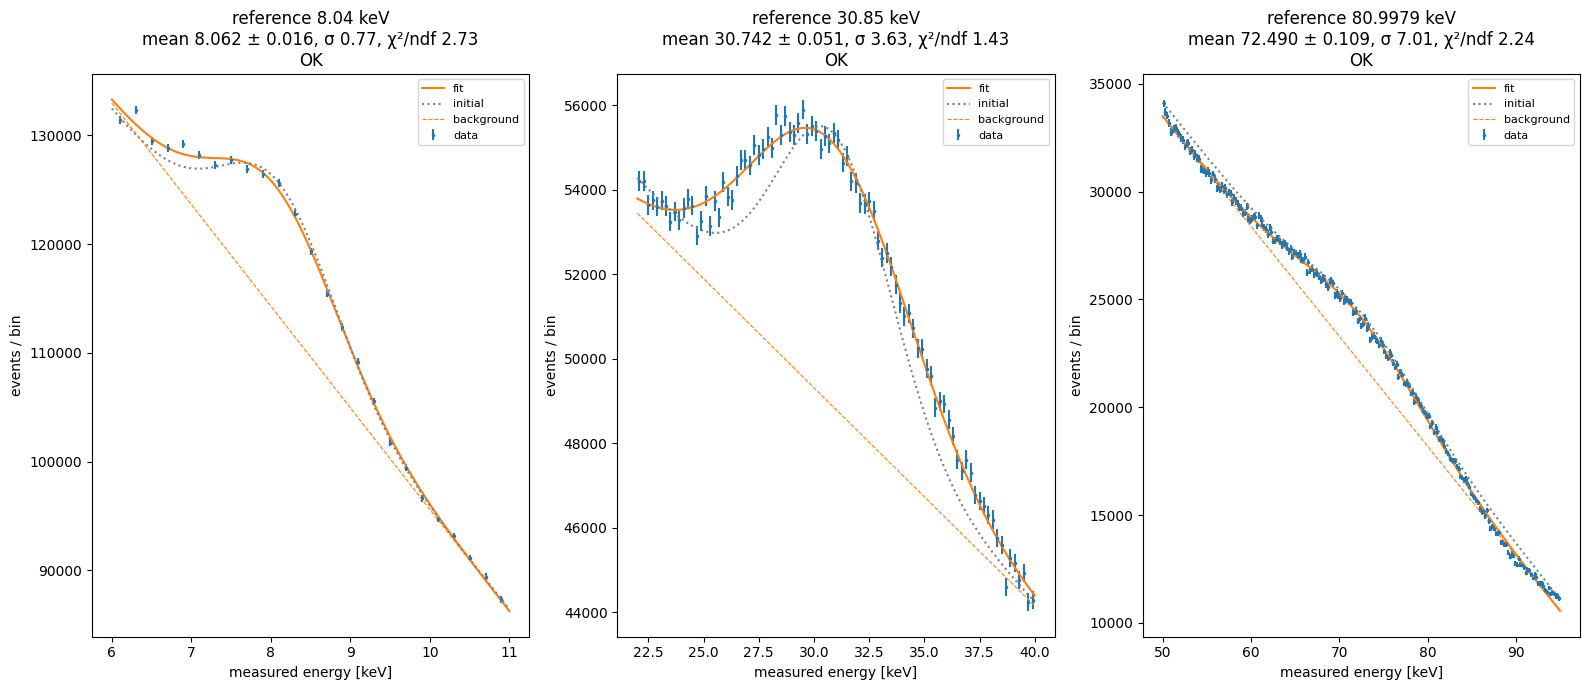

In [ ]:
REFERENCE_KEV=np.array([8.04,30.85,80.9979])  # 採用する基準エネルギー [keV]。要確認
REFERENCES_CONFIRMED=True
# ゲイン適用後のfit範囲 [keV]。全イベントのスペクトルでは線が右下がりの連続成分に乗るので、線の前後だけを含める
# (4 keV 付近のトゲや、窓の左端の高いところを拾わないように)。81 keV は山ではなく肩で、窓と背景の形で中心が数 keV 動く
WINDOWS=[(6.,11.),(22.,40.),(50.,95.)]
# 手動の初期値・固定値(ピークごと。{} なら自動)。例: {'mean':78.,'sigma':6.}
INITIAL=[{},{},{}]
FIXED=[{},{},{}]
CHI2NDF_MAX=5.0  # χ²/ndfの上限 [dimensionless]
SIGNIFICANCE_MIN=3.0  # ガウス高さ/標準誤差の下限 [dimensionless]
fits=[fit_peak(edges,counts,w,CHI2NDF_MAX,SIGNIFICANCE_MIN,initial=i,fixed=f) for w,i,f in zip(WINDOWS,INITIAL,FIXED)]
fig,axs=plt.subplots(1,3,figsize=(16,7))
for ax,r,eref in zip(axs,fits,REFERENCE_KEV):
    sel=(x>=r['window'][0])&(x<=r['window'][1]);ax.errorbar(x[sel],counts[sel],np.sqrt(np.maximum(counts[sel],1)),fmt='.',ms=3,label='data')
    xx=np.linspace(*r['window'],300);ax.plot(xx,gaussian_linear(xx,*r['parameters']),label='fit')
    p0=[r['initial'][k] for k in ('amplitude','mean','sigma','b0','b1')];ax.plot(xx,gaussian_linear(xx,*p0),':',color='gray',label='initial')
    a,m,s,b0,b1=r['parameters'];ax.plot(xx,b0+b1*(xx-m),':',color='C3',lw=1.2,label='background')
    # the Gaussian alone is far below the background: on its own axis (right)
    ax2=ax.twinx();ax2.plot(xx,a*np.exp(-.5*((xx-m)/s)**2),':',color='C2',lw=1.2);ax2.set_ylim(0,None)
    ax2.set_ylabel('Gaussian alone [events / bin]',color='C2');ax2.tick_params(axis='y',colors='C2')
    ax.plot([],[],':',color='C2',label='Gaussian (right axis)')
    ok='OK' if r['accepted'] else 'NG: '+', '.join(r['reasons'])
    ax.set(title=f"reference {eref:g} keV\nmean {r['mean']:.3f} ± {r['mean_error']:.3f}, σ {r['sigma']:.2f}, χ²/ndf {r['chi2ndf']:.2f}\n{ok}",
           xlabel='measured energy [keV]',ylabel='events / bin')
    ax.legend(fontsize=8)
    print({k:r[k] for k in ('mean','mean_error','sigma','chi2ndf','initial','fixed','accepted','reasons')})
fig.tight_layout();fig.savefig(OUT/'peak_fits.png',dpi=150);plt.show()

## 4. 全体の二次補正

`E_corrected = a0 + a1 E_gain + a2 E_gain²`。3点を通すため自由度は0で、補正式のχ²による検証はできません。
ピーク中心の標準誤差を係数の3×3共分散に一次伝播します（ピーク間独立・基準エネルギー固定）。系統誤差は含みません。
3ピークの間で単調増加することを確認します。範囲外は端点の接線で連続的に延長し、負のエネルギーは0とします。

{
  "format": "TPC_ENERGY_QUADRATIC_V1",
  "coefficients": [
    0.6834243773041724,
    0.888035283551493,
    0.0030335543907584568
  ],
  "range_keV": [
    8.06207122990672,
    72.49005723741206
  ],
  "outside": "tangent",
  "covariance": [
    [
      0.001826791499572182,
      -0.0002078133202776133,
      2.885666138616742e-06
    ],
    [
      -0.00020781332027761332,
      2.6972728168150833e-05,
      -3.899268868869974e-07
    ],
    [
      2.885666138616742e-06,
      -3.899268868869974e-07,
      6.308755955352158e-09
    ]
  ],
  "coefficient_units": [
    "keV",
    "1",
    "1/keV"
  ],
  "means_keV": [
    8.06207122990672,
    30.741694734147956,
    72.49005723741206
  ],
  "mean_errors_keV": [
    0.015911131545997718,
    0.05073694376934518,
    0.10888140545358213
  ],
  "references_keV": [
    8.04,
    30.85,
    80.9979
  ],
  "uncertainty_assumptions": "independent peak means; fixed reference energies; first-order statistical propagation",
  "ndf": 0,
  

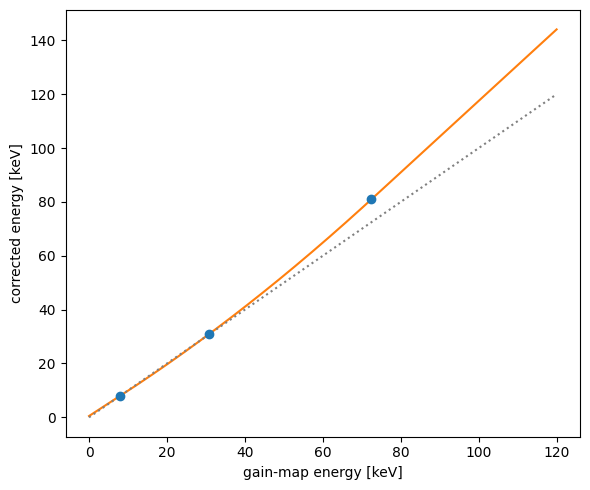

In [34]:
if not all(r['accepted'] for r in fits):raise RuntimeError('採用条件に通らないピークがあります。fit範囲・ピーク形状を確認してください')
cal=quadratic_calibration([r['mean'] for r in fits],[r['mean_error'] for r in fits],REFERENCE_KEV)
cal.update(gain_map=str(GAIN_MAP.resolve()),inputs=[str(p.resolve()) for p in RAWS],base_window_samples=BASE_WINDOW,threshold_ADU=THRESHOLD,selection='all events; uncalibrated contributions zero',peak_fits=fits)
print(json.dumps(cal,ensure_ascii=False,indent=2))
fig,ax=plt.subplots(figsize=(6,5));ax.errorbar(cal['means_keV'],REFERENCE_KEV,xerr=cal['mean_errors_keV'],fmt='o')
xx=np.linspace(0,120,500);ax.plot(xx,evaluate(xx,cal));ax.plot(xx,xx,ls=':',color='gray');ax.set(xlabel='gain-map energy [keV]',ylabel='corrected energy [keV]');fig.tight_layout();fig.savefig(OUT/'energy_correction.png',dpi=150);plt.show()


## 5. 補正後のスペクトルと保存
ここでの補正後ヒストグラムは、入力の各ビン（0.2 keV）の中身を補正後の区間に一様に広げて配り直した表示です。イベントごとの補正結果とは、ビンの中での分布の仮定の分だけ違います。較正ファイルは基準値の確認後だけ出力します。

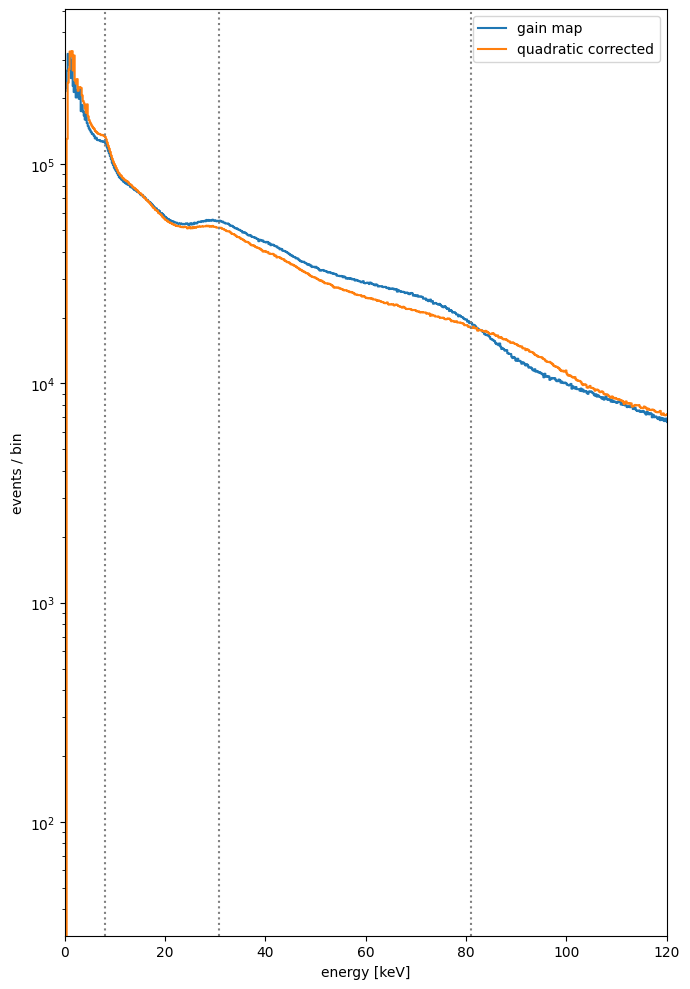

RuntimeError: REFERENCE_KEVを確認し、REFERENCES_CONFIRMED=Trueにしてから保存してください

In [35]:
# 各入力ビンの中身を、補正後の区間 [E'(下端), E'(上端)] に一様に広げて出力ビンへ配る
# (ビン中心だけを写すと、補正の傾きが1より大きい所で空のビン、小さい所で2倍のビンができる)
cum=np.concatenate([[0.],np.cumsum(counts)])
corrected=np.diff(np.interp(edges,evaluate(edges,cal),cum))
fig,ax=plt.subplots(figsize=(7,10));ax.step(x,counts,where='mid',label='gain map');ax.step(x,corrected,where='mid',label='quadratic corrected')
for e in REFERENCE_KEV:ax.axvline(e,ls=':',color='gray')
ax.set(xlim=(0,120),xlabel='energy [keV]',ylabel='events / bin',yscale='log');ax.legend();fig.tight_layout();fig.savefig(OUT/'spectrum_before_after.png',dpi=150);plt.show()
if not REFERENCES_CONFIRMED:raise RuntimeError('REFERENCE_KEVを確認し、REFERENCES_CONFIRMED=Trueにしてから保存してください')
write_correction(OUT/'tpc_energy_correction.dat',cal)
print('wrote',OUT/'tpc_energy_correction.dat')


## 6. 再構成チェーンへの適用

ゲインマップと全体補正を両方指定します。補正は各イベントのTPC全体エネルギーに一度だけ適用されます。

```bash
python3 run_script/run_chain.py smile3_tpc_energy --root-input "<入力raw_ROOT>" -o "<出力ROOT>" \
    --set TPC_Calibration.NoCalData=false \
    --set TPC_Calibration.ParameterFile="<gain_map.dat>" \
    --set TPC_Calibration.energy_correction_file="<tpc_energy_correction.dat>"
```

`smile3_reconstruct`でも同じ指定で適用できます。Spectrumが補正後、Spectrum_GainMapが補正前です。
補正ファイルの係数誤差はJSONに保存します。チェーンのイベントエネルギーへの誤差伝播は行いません。
